# Volcanic Field Simulations

Notebook to:
+ perform leave-k-out analyses on observed vent data
+ generate a synthetic dataset of vents within a user-defined volcanic field
+ analyse the results from both analyses
+ generate summary figures

Uses the `volcanicfieldsim` module.

Please cite:
>Miller et al. (submitted). Evolution of the Auckland Volcanic Field (New Zealand) boundary.
__________
Author: E. Judd

Created: April 2026

Last modified: November 2026

## Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import importlib
import volcanicfieldsim as vfs
importlib.reload(vfs)
mpl.rcParams['font.family'] = 'Arial'

## AVF Ellipse Parameters

In [2]:
startrect = (28884, 16481) # major x full minor (m) from Spörli & Eastwood 1997
center = (76614, 71891)
rotationdeg = 90 - 2.6
boundingellipse = {
    'center': center,
    'a': startrect[0] / 2,
    'b': startrect[1] / 2,
    'rotationdeg': rotationdeg
}
unitscale = 1.0 # everything in metres

# set the seed
baseseed = 123


## Observed Data

### Load observed data and calulculate the hull info

In [ ]:
# read in vent data
vents = pd.read_csv('./Data/AVF vent ages and locations.csv')

# remove vents without ages
vents = vents.dropna(subset=['age'])

# remove first Rangitoto vent
vents = vents[vents['name'] != 'Rangitoto1']

# determine which percentages to increase the bounding ellipse for area ratio scenarios (Fig. 7A)
area_prct = [5, 10, 15, 20, 25]

# calculate hull info for all vents and save output to a CSV file
vents = vfs.sequentialhullinfo(vents, 
                               startrect = startrect,
                               area_prct=area_prct,
                               savepath='./Outputs/AVFvents hull areas and distances.csv')

# subset young vents (< 63 ka)
youngvents = vents[vents['age'] < 63]

# print number of vents
print(f"Number of vents with ages: {len(vents)}")
print(f"Number of young vents (< 63 ka): {len(youngvents)}")

Number of vents with ages: 51
Number of young vents (< 63 ka): 35


### Run the leave-k-out analyses

In [4]:
# Run the analysis for all permutations of both leave-1-out and leave-2-out
points = vents[['easting','northing']].to_numpy(float)
results = vfs.withholdkensemble(points, k=[1,2], replacement=False)

# Summarize the results in terms of the buffer distance required to capture a target percentile
# of withheld vents (e.g., here, we specify 95% and 99%)
summaries_buff = vfs.summarizewithholdk(results, target_percentile=[0.95, 0.99])
target_buffer_m_k1 = summaries_buff[0.95][1]['target_buffer_m']
target_buffer_m_k2 = summaries_buff[0.95][2]['target_buffer_m']
print(f"Target buffer distance for 95% coverage with leave-1-out: {target_buffer_m_k1:.2f} m")
print(f"Target buffer distance for 95% coverage with leave-2-out: {target_buffer_m_k2:.2f} m")

# Summarize the results in terms of the percentile of vents within a specified target buffer
# (e.g., here, we specify a buffer of 0 m, which is equivalent to asking what percent 
# of vents are within the existing hull)
summaries_pct = vfs.summarizewithholdk(results, target_buffer_m=0)
pct_k1 = summaries_pct[0][1]['target_percentile']
pct_k2 = summaries_pct[0][2]['target_percentile']
print(f"Percent of vents within the existing hull (i.e., 0 m buffer) with leave-1-out: {pct_k1:.2f}%")
print(f"Percent of vents within the existing hull (i.e., 0 m buffer) with leave-2-out: {pct_k2:.2f}%")


Target buffer distance for 95% coverage with leave-1-out: 1576.73 m
Target buffer distance for 95% coverage with leave-2-out: 1783.98 m
Percent of vents within the existing hull (i.e., 0 m buffer) with leave-1-out: 0.75%
Percent of vents within the existing hull (i.e., 0 m buffer) with leave-2-out: 0.74%


### Record results for leave-k-out with target buffers 
Buffers range between 0 and 12000 m in 500 m increments.
Record results for all permutations *and* for only those permutationswhere all witheld vents are young (<63 ka)

(data used in Figure 9)

In [5]:
target_buffer_m = np.arange(0, 12001, 500)
summary_all = vfs.summarizewithholdk(results, target_buffer_m=target_buffer_m)
young_idx = youngvents.index.to_numpy()
results_young = (
    results
    .groupby('simid')
    .filter(lambda g: np.all(np.isin(g['withheldindex'], young_idx)))
)
summary_young = vfs.summarizewithholdk(results_young, target_buffer_m=target_buffer_m)

# Save the summaries to a data frame
summary_all_df = pd.DataFrame({
    'target_buffer_m': target_buffer_m,
    'pct_k1': [summary_all[b][1]['target_percentile'] for b in target_buffer_m],
    'pct_k2': [summary_all[b][2]['target_percentile'] for b in target_buffer_m],
})

summary_young_df = pd.DataFrame({
    'target_buffer_m': target_buffer_m,
    'pct_k1': [summary_young[b][1]['target_percentile'] for b in target_buffer_m],
    'pct_k2': [summary_young[b][2]['target_percentile'] for b in target_buffer_m],
})

# Save the data frame to a CSV file
summary_all_df.to_csv('./Outputs/AVF withhold-k buffers.csv', index=False)
summary_young_df.to_csv('./Outputs/AVF withhold-k buffers (all vents, young results).csv', index=False)

## Synthetic dataset

### Run ensemble

In [8]:
# select the number of iterations
nsims = 1000

# select the number of eruptions in each iteration
neruptions = 250

# run the simulation and compute percentiles for the synthetic vents
syntheticventsens = vfs.runensemble(
    n_sims=nsims, n_eruptions=neruptions, coordsystem='cartesian',
    center=center, startrect=startrect, rotationdeg=rotationdeg,
    unitscale=unitscale, baseseed=baseseed)
syntheticventspctls = vfs.computepercentiles(syntheticventsens,
                                             percentiles=[2.5, 16, 50, 84, 97.5, 100])
syntheticventsens.head()


,simid,t,x,y,hullarea,arearatio,distprev,withinprevhull,disttoprevhull
0,1,1,74726.049798,79446.306933,0.000000e+00,0.000000,NaN,NaN,NaN
1,1,2,74736.550661,79722.992639,0.000000e+00,0.000000,276.884900,False,276.884900
2,1,3,70367.567695,62689.821046,5.149861e+05,0.001377,17584.565580,False,17314.045903
3,1,4,76805.652183,75819.642129,2.614852e+07,0.069938,14623.307886,False,2925.577415
4,1,5,76216.056699,75003.952998,2.614852e+07,0.069938,1006.464898,True,0.000000


### Plot results

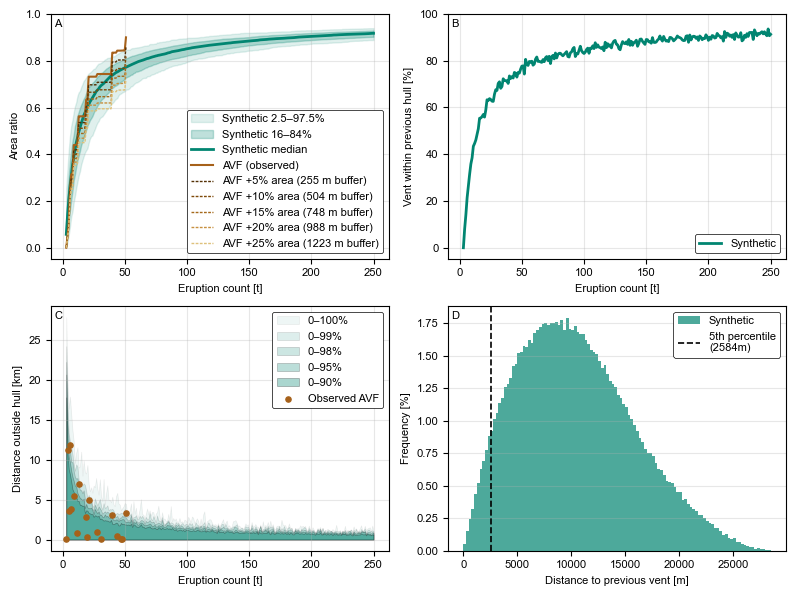

[<Figure size 800x600 with 4 Axes>]

In [ ]:
figure = [('SyntheticSummary', ['arearatio', 'prctinside', 'distanceoutside', 'distprevhist'])]
vfs.summaryplots(
    ensemble=syntheticventsens,
    percentiles=syntheticventspctls,
    observed=vents,
    boundingellipse=boundingellipse,
    areapctratiocol=[f'arearatio_{p}%' for p in area_prct],
    figures=figure,
    savefigs=True,
)
